In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

BASE_DIR = Path("..")  # Run this from the notebooks folder

RAW_FILE = BASE_DIR / "data" / "raw" / "online_retail_II.xlsx"
PROCESSED_DIR = BASE_DIR / "data" / "processed"
CHART_DIR = BASE_DIR / "outputs" / "charts"
OUTPUT_DIR = BASE_DIR / "outputs"

for folder in [PROCESSED_DIR, CHART_DIR, OUTPUT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(
    BASE_DIR / "data" / "raw" / "online_retail_II.csv"
)


print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Dataset shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 136.6 MB


None

In [11]:
df.columns = df.columns.str.strip()

print("Columns:")
print(df.columns.tolist())

display(df.isnull().sum())
display(df.describe(include="all").T)

Columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']


Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Invoice,1067371,53628,537434,1350,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,1067371,5305,85123A,5829,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,1062989,5698,WHITE HANGING HEART T-LIGHT HOLDER,5918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,"1,067,371.00",NaN,NaN,NaN,9.94,172.71,"-80,995.00",1.00,3.00,10.00,"80,995.00"
InvoiceDate,1067371,47635,2010-12-06 16:57:00,1350,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,"1,067,371.00",NaN,NaN,NaN,4.65,123.55,"-53,594.36",1.25,2.10,4.15,"38,970.00"
Customer ID,"824,364.00",NaN,NaN,NaN,"15,324.64","1,697.46","12,346.00","13,975.00","15,255.00","16,797.00","18,287.00"
Country,1067371,43,United Kingdom,981330,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
cleaning_log = []

def log_cleaning_step(rule, rows_before, rows_after, explanation):
    removed = rows_before - rows_after

    cleaning_log.append({
        "Rule": rule,
        "Rows Before": rows_before,
        "Rows After": rows_after,
        "Rows Removed": removed,
        "Explanation": explanation
    })

initial_rows = len(df)

print("Initial rows:", initial_rows)

Initial rows: 1067371


In [13]:
rows_before = len(df)

clean_df = df.dropna(subset=["Customer ID"]).copy()

log_cleaning_step(
    "Remove missing Customer IDs",
    rows_before,
    len(clean_df),
    "Customers without an identifiable Customer ID cannot be included in customer-level cohort analysis."
)

missing_customer_pct = (
    (rows_before - len(clean_df)) / rows_before
) * 100

print(f"Rows removed: {rows_before - len(clean_df):,}")
print(f"Percentage removed: {missing_customer_pct:.2f}%")

Rows removed: 243,007
Percentage removed: 22.77%


In [14]:
rows_before = len(clean_df)

clean_df["Invoice"] = clean_df["Invoice"].astype(str).str.strip()

cancellations = clean_df[
    clean_df["Invoice"].str.startswith("C", na=False)
].copy()

clean_df = clean_df[
    ~clean_df["Invoice"].str.startswith("C", na=False)
].copy()

log_cleaning_step(
    "Remove cancellation invoices",
    rows_before,
    len(clean_df),
    "Invoices beginning with C are treated as cancellations and excluded from sales revenue."
)

print("Cancellation rows:", len(cancellations))
print("Cancellation revenue/quantity records are retained separately for reporting.")

Cancellation rows: 18744
Cancellation revenue/quantity records are retained separately for reporting.


In [15]:
rows_before = len(clean_df)

invalid_quantity = (clean_df["Quantity"] <= 0).sum()
invalid_price = (clean_df["Price"] <= 0).sum()

clean_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["Price"] > 0)
].copy()

log_cleaning_step(
    "Remove non-positive Quantity and Price",
    rows_before,
    len(clean_df),
    f"Removed rows with non-positive quantity or price. Initial invalid quantity rows: {invalid_quantity}; invalid price rows: {invalid_price}. Some rows may overlap."
)

print("Invalid quantity rows before removal:", invalid_quantity)
print("Invalid price rows before removal:", invalid_price)

Invalid quantity rows before removal: 0
Invalid price rows before removal: 71


In [16]:
non_product_codes = ["POST", "M", "D"]

rows_before = len(clean_df)

clean_df["StockCode"] = (
    clean_df["StockCode"].astype(str).str.strip().str.upper()
)

clean_df = clean_df[
    ~clean_df["StockCode"].isin(non_product_codes)
].copy()

log_cleaning_step(
    "Remove confirmed non-product stock codes",
    rows_before,
    len(clean_df),
    f"Excluded exact StockCode matches: {non_product_codes}."
)

print("Rows after stock code filtering:", len(clean_df))

Rows after stock code filtering: 802997


In [19]:
clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"],
    errors="coerce"
)

clean_df = clean_df.dropna(subset=["InvoiceDate"]).copy()

clean_df["revenue"] = (
    clean_df["Quantity"] * clean_df["Price"]
)

clean_df["Order_month"] = (
    clean_df["InvoiceDate"].dt.to_period("M")
)

clean_df["Customer ID"] = clean_df["Customer ID"].astype(int)

print("Final cleaned shape:", clean_df.shape)
print("Date range:", clean_df["InvoiceDate"].min(), "to", clean_df["InvoiceDate"].max())
print("Total revenue:", f"£{clean_df['revenue'].sum():,.2f}")

Final cleaned shape: (802997, 10)
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Total revenue: £17,464,127.68


In [17]:
cleaning_log_df = pd.DataFrame(cleaning_log)

display(cleaning_log_df)

cleaning_log_df.to_csv(
    PROCESSED_DIR / "cleaning_log.csv",
    index=False
)

clean_df.to_csv(
    PROCESSED_DIR / "cleaned_online_retail.csv",
    index=False
)

print("Cleaning log and cleaned dataset saved.")

,Rule,Rows Before,Rows After,Rows Removed,Explanation
0,Remove missing Customer IDs,1067371,824364,243007,Customers without an identifiable Customer ID ...
1,Remove cancellation invoices,824364,805620,18744,Invoices beginning with C are treated as cance...
2,Remove non-positive Quantity and Price,805620,805549,71,Removed rows with non-positive quantity or pri...
3,Remove confirmed non-product stock codes,805549,802997,2552,"Excluded exact StockCode matches: ['POST', 'M'..."


Cleaning log and cleaned dataset saved.


In [20]:
first_purchase = (
    clean_df.groupby("Customer ID")["Order_month"]
    .min()
    .rename("cohort_month")
)

clean_df = clean_df.join(
    first_purchase,
    on="Customer ID"
)

display(clean_df[
    ["Customer ID", "Order_month", "cohort_month"]
].head())

,Customer ID,Order_month,cohort_month
0,13085,2009-12,2009-12
1,13085,2009-12,2009-12
2,13085,2009-12,2009-12
3,13085,2009-12,2009-12
4,13085,2009-12,2009-12


In [21]:
clean_df["month_index"] = (
    (clean_df["Order_month"] - clean_df["cohort_month"])
    .apply(lambda x: x.n)
)

display(clean_df[
    ["Customer ID", "Order_month", "cohort_month", "month_index"]
].head(10))

,Customer ID,Order_month,cohort_month,month_index
0,13085,2009-12,2009-12,0
1,13085,2009-12,2009-12,0
2,13085,2009-12,2009-12,0
3,13085,2009-12,2009-12,0
4,13085,2009-12,2009-12,0
5,13085,2009-12,2009-12,0
6,13085,2009-12,2009-12,0
7,13085,2009-12,2009-12,0
8,13085,2009-12,2009-12,0
9,13085,2009-12,2009-12,0


In [22]:
cohort_table = clean_df.pivot_table(
    index="cohort_month",
    columns="month_index",
    values="Customer ID",
    aggfunc="nunique"
)

cohort_sizes = cohort_table[0]

display(cohort_table)

month_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
cohort_month,,,,,,,,,,,,,,,,,,,,,,,,,
2009-12,952.00,336.00,317.00,405.00,362.00,342.00,360.00,327.00,321.00,344.00,401.00,472.00,359.00,269.00,232.00,288.00,250.00,288.00,270.00,246.00,242.00,299.00,289.00,386.00,187.00
2010-01,382.00,79.00,119.00,117.00,101.00,115.00,99.00,88.00,106.00,121.00,115.00,66.00,84.00,67.00,72.00,57.00,90.00,75.00,71.00,75.00,93.00,74.00,94.00,21.00,NaN
2010-02,375.00,88.00,85.00,110.00,92.00,74.00,72.00,108.00,96.00,104.00,43.00,47.00,57.00,66.00,46.00,76.00,60.00,61.00,54.00,86.00,86.00,62.00,22.00,NaN,NaN
2010-03,439.00,84.00,102.00,106.00,103.00,90.00,109.00,134.00,122.00,48.00,50.00,63.00,88.00,72.00,88.00,75.00,77.00,69.00,78.00,89.00,94.00,35.00,NaN,NaN,NaN
2010-04,293.00,56.00,56.00,47.00,54.00,65.00,81.00,77.00,31.00,32.00,22.00,41.00,41.00,46.00,46.00,46.00,41.00,44.00,53.00,66.00,17.00,NaN,NaN,NaN,NaN
2010-05,254.00,40.00,43.00,44.00,45.00,65.00,54.00,32.00,15.00,21.00,29.00,34.00,39.00,39.00,25.00,32.00,35.00,42.00,39.00,12.00,NaN,NaN,NaN,NaN,NaN
2010-06,267.00,47.00,50.00,55.00,62.00,76.00,34.00,24.00,22.00,30.00,28.00,37.00,40.00,33.00,30.00,33.00,35.00,54.00,13.00,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,186.00,29.00,34.00,55.00,54.00,26.00,21.00,27.00,27.00,21.00,25.00,27.00,24.00,25.00,36.00,32.00,44.00,15.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,162.00,32.00,47.00,53.00,27.00,19.00,16.00,21.00,22.00,21.00,21.00,19.00,24.00,28.00,28.00,32.00,12.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
retention_matrix = cohort_table.divide(
    cohort_sizes,
    axis=0
) * 100

last_month = clean_df["Order_month"].max()

for cohort in retention_matrix.index:
    max_index = (last_month - cohort).n

    retention_matrix.loc[
        cohort,
        retention_matrix.columns > max_index
    ] = np.nan

retention_matrix = retention_matrix.round(2)

display(retention_matrix)

month_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
cohort_month,,,,,,,,,,,,,,,,,,,,,,,,,
2009-12,100.00,35.29,33.30,42.54,38.03,35.92,37.82,34.35,33.72,36.13,42.12,49.58,37.71,28.26,24.37,30.25,26.26,30.25,28.36,25.84,25.42,31.41,30.36,40.55,19.64
2010-01,100.00,20.68,31.15,30.63,26.44,30.10,25.92,23.04,27.75,31.68,30.10,17.28,21.99,17.54,18.85,14.92,23.56,19.63,18.59,19.63,24.35,19.37,24.61,5.50,NaN
2010-02,100.00,23.47,22.67,29.33,24.53,19.73,19.20,28.80,25.60,27.73,11.47,12.53,15.20,17.60,12.27,20.27,16.00,16.27,14.40,22.93,22.93,16.53,5.87,NaN,NaN
2010-03,100.00,19.13,23.23,24.15,23.46,20.50,24.83,30.52,27.79,10.93,11.39,14.35,20.05,16.40,20.05,17.08,17.54,15.72,17.77,20.27,21.41,7.97,NaN,NaN,NaN
2010-04,100.00,19.11,19.11,16.04,18.43,22.18,27.65,26.28,10.58,10.92,7.51,13.99,13.99,15.70,15.70,15.70,13.99,15.02,18.09,22.53,5.80,NaN,NaN,NaN,NaN
2010-05,100.00,15.75,16.93,17.32,17.72,25.59,21.26,12.60,5.91,8.27,11.42,13.39,15.35,15.35,9.84,12.60,13.78,16.54,15.35,4.72,NaN,NaN,NaN,NaN,NaN
2010-06,100.00,17.60,18.73,20.60,23.22,28.46,12.73,8.99,8.24,11.24,10.49,13.86,14.98,12.36,11.24,12.36,13.11,20.22,4.87,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,100.00,15.59,18.28,29.57,29.03,13.98,11.29,14.52,14.52,11.29,13.44,14.52,12.90,13.44,19.35,17.20,23.66,8.06,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,100.00,19.75,29.01,32.72,16.67,11.73,9.88,12.96,13.58,12.96,12.96,11.73,14.81,17.28,17.28,19.75,7.41,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


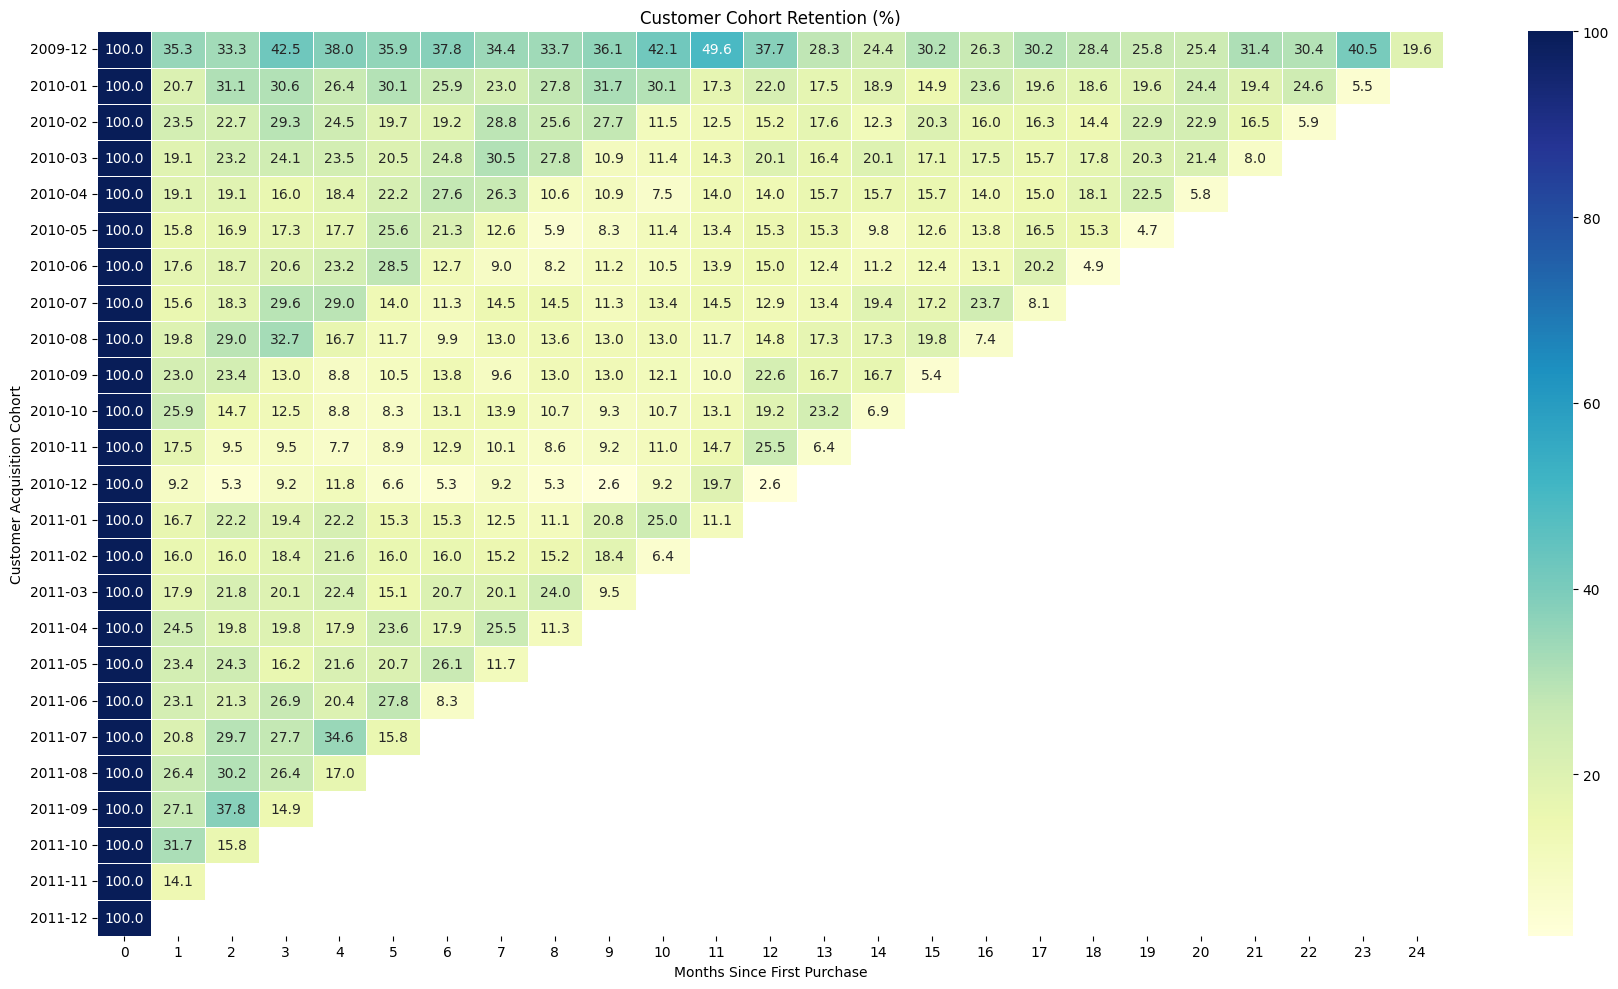

In [24]:
plt.figure(figsize=(18, 10))

sns.heatmap(
    retention_matrix,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5,
    mask=retention_matrix.isna()
)

plt.title("Customer Cohort Retention (%)")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Acquisition Cohort")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "customer_retention_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
month_1_retention = (
    retention_matrix[1]
    .dropna()
    .sort_values(ascending=False)
)

display(month_1_retention.to_frame("Month 1 Retention (%)"))

print("Best Month 1 cohort:", month_1_retention.idxmax())
print("Best Month 1 retention:", f"{month_1_retention.max():.2f}%")

print("Worst Month 1 cohort:", month_1_retention.idxmin())
print("Worst Month 1 retention:", f"{month_1_retention.min():.2f}%")

,Month 1 Retention (%)
cohort_month,
2009-12,35.29
2011-10,31.67
2011-09,27.13
2011-08,26.42
2010-10,25.87
2011-04,24.53
2010-02,23.47
2011-05,23.42
2011-06,23.15


Best Month 1 cohort: 2009-12
Best Month 1 retention: 35.29%
Worst Month 1 cohort: 2010-12
Worst Month 1 retention: 9.21%


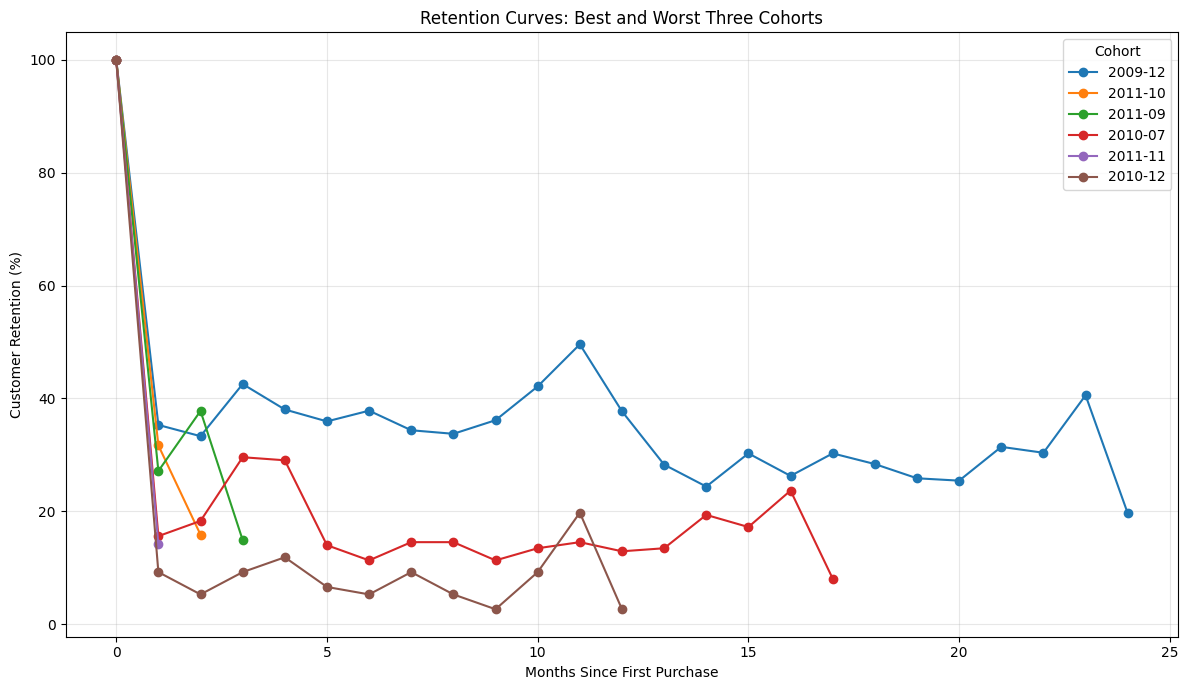

In [26]:
best_three = month_1_retention.head(3).index
worst_three = month_1_retention.tail(3).index

selected_cohorts = list(best_three) + list(worst_three)

plt.figure(figsize=(12, 7))

for cohort in selected_cohorts:
    plt.plot(
        retention_matrix.columns,
        retention_matrix.loc[cohort],
        marker="o",
        label=str(cohort)
    )

plt.title("Retention Curves: Best and Worst Three Cohorts")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Retention (%)")
plt.legend(title="Cohort")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    CHART_DIR / "best_worst_retention_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
cohort_revenue = clean_df.pivot_table(
    index="cohort_month",
    columns="month_index",
    values="revenue",
    aggfunc="sum",
    fill_value=0
)

display(cohort_revenue.round(2))

month_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
cohort_month,,,,,,,,,,,,,,,,,,,,,,,,,
2009-12,"681,544.72","378,706.20","293,705.31","376,819.07","304,544.52","303,312.49","301,201.73","312,722.23","329,532.06","374,694.78","452,497.19","570,236.29","527,059.82","307,714.56","214,114.16","251,288.87","160,087.40","276,028.91","278,983.75","252,063.54","269,970.84","373,764.27","410,620.63","443,635.49","162,525.33"
2010-01,"160,301.69","38,842.05","50,616.89","57,031.94","58,262.46","60,782.01","51,879.95","47,562.17","59,028.34","74,284.37","76,049.60","61,507.24","42,305.97","34,611.90","48,047.35","30,832.22","49,826.83","39,901.11","47,582.51","42,279.24","59,045.76","59,229.44","58,088.02","8,232.11",0.00
2010-02,"167,417.32","32,819.94","53,389.27","53,408.66","43,302.54","39,591.03","37,687.63","52,460.69","52,878.74","54,437.92","35,997.16","18,786.47","27,262.65","35,154.87","20,548.26","37,933.76","29,453.58","33,298.52","25,175.65","45,083.50","45,494.54","38,855.87","11,057.57",0.00,0.00
2010-03,"208,721.29","49,925.44","51,750.68","64,406.41","50,296.72","55,982.80","65,288.57","81,088.42","76,754.42","35,040.28","24,150.46","30,016.29","43,416.27","41,784.62","47,134.22","31,665.15","42,836.24","49,976.71","47,215.24","56,856.17","61,426.59","16,852.74",0.00,0.00,0.00
2010-04,"123,280.10","18,782.35","20,697.24","29,935.85","22,253.44","30,614.32","34,611.40","32,126.05","15,031.20","17,374.52","6,458.09","16,839.48","15,210.91","22,385.14","16,490.74","22,339.75","17,673.39","19,349.58","25,720.44","29,416.20","4,924.97",0.00,0.00,0.00,0.00
2010-05,"109,599.90","13,592.50","14,089.05","12,805.18","16,811.31","31,105.76","23,367.51","13,626.49","5,883.27","7,024.21","9,274.83","12,940.96","17,210.60","18,056.25","9,631.04","14,590.95","22,115.68","17,691.82","15,721.99","3,422.64",0.00,0.00,0.00,0.00,0.00
2010-06,"128,733.47","15,996.36","22,190.81","25,779.05","34,975.14","47,943.61","24,974.39","17,135.23","23,880.97","28,162.30","12,000.35","29,876.68","40,124.65","16,082.42","45,811.64","18,522.02","34,853.70","27,599.25","4,127.64",0.00,0.00,0.00,0.00,0.00,0.00
2010-07,"69,597.34","8,261.90","13,503.63","24,319.65","28,241.30","15,555.27","8,744.80","10,217.40","9,937.58","9,798.37","8,921.44","12,503.11","12,004.72","14,214.67","15,577.83","15,465.63","22,144.12","7,065.30",0.00,0.00,0.00,0.00,0.00,0.00,0.00
2010-08,"60,883.23","11,341.25","19,049.32","23,864.54","22,104.77","5,432.59","5,118.13","7,525.94","9,776.13","9,809.21","7,147.44","6,895.78","10,201.25","12,636.19","14,609.70","17,395.04","5,921.89",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [28]:
for cohort in cohort_revenue.index:
    max_index = (last_month - cohort).n

    cohort_revenue.loc[
        cohort,
        cohort_revenue.columns > max_index
    ] = np.nan

display(cohort_revenue.round(2))

month_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
cohort_month,,,,,,,,,,,,,,,,,,,,,,,,,
2009-12,"681,544.72","378,706.20","293,705.31","376,819.07","304,544.52","303,312.49","301,201.73","312,722.23","329,532.06","374,694.78","452,497.19","570,236.29","527,059.82","307,714.56","214,114.16","251,288.87","160,087.40","276,028.91","278,983.75","252,063.54","269,970.84","373,764.27","410,620.63","443,635.49","162,525.33"
2010-01,"160,301.69","38,842.05","50,616.89","57,031.94","58,262.46","60,782.01","51,879.95","47,562.17","59,028.34","74,284.37","76,049.60","61,507.24","42,305.97","34,611.90","48,047.35","30,832.22","49,826.83","39,901.11","47,582.51","42,279.24","59,045.76","59,229.44","58,088.02","8,232.11",NaN
2010-02,"167,417.32","32,819.94","53,389.27","53,408.66","43,302.54","39,591.03","37,687.63","52,460.69","52,878.74","54,437.92","35,997.16","18,786.47","27,262.65","35,154.87","20,548.26","37,933.76","29,453.58","33,298.52","25,175.65","45,083.50","45,494.54","38,855.87","11,057.57",NaN,NaN
2010-03,"208,721.29","49,925.44","51,750.68","64,406.41","50,296.72","55,982.80","65,288.57","81,088.42","76,754.42","35,040.28","24,150.46","30,016.29","43,416.27","41,784.62","47,134.22","31,665.15","42,836.24","49,976.71","47,215.24","56,856.17","61,426.59","16,852.74",NaN,NaN,NaN
2010-04,"123,280.10","18,782.35","20,697.24","29,935.85","22,253.44","30,614.32","34,611.40","32,126.05","15,031.20","17,374.52","6,458.09","16,839.48","15,210.91","22,385.14","16,490.74","22,339.75","17,673.39","19,349.58","25,720.44","29,416.20","4,924.97",NaN,NaN,NaN,NaN
2010-05,"109,599.90","13,592.50","14,089.05","12,805.18","16,811.31","31,105.76","23,367.51","13,626.49","5,883.27","7,024.21","9,274.83","12,940.96","17,210.60","18,056.25","9,631.04","14,590.95","22,115.68","17,691.82","15,721.99","3,422.64",NaN,NaN,NaN,NaN,NaN
2010-06,"128,733.47","15,996.36","22,190.81","25,779.05","34,975.14","47,943.61","24,974.39","17,135.23","23,880.97","28,162.30","12,000.35","29,876.68","40,124.65","16,082.42","45,811.64","18,522.02","34,853.70","27,599.25","4,127.64",NaN,NaN,NaN,NaN,NaN,NaN
2010-07,"69,597.34","8,261.90","13,503.63","24,319.65","28,241.30","15,555.27","8,744.80","10,217.40","9,937.58","9,798.37","8,921.44","12,503.11","12,004.72","14,214.67","15,577.83","15,465.63","22,144.12","7,065.30",NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,"60,883.23","11,341.25","19,049.32","23,864.54","22,104.77","5,432.59","5,118.13","7,525.94","9,776.13","9,809.21","7,147.44","6,895.78","10,201.25","12,636.19","14,609.70","17,395.04","5,921.89",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [29]:
revenue_retention = cohort_revenue.divide(
    cohort_revenue[0],
    axis=0
) * 100

revenue_retention = revenue_retention.round(2)

display(revenue_retention)

month_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
cohort_month,,,,,,,,,,,,,,,,,,,,,,,,,
2009-12,100.00,55.57,43.09,55.29,44.68,44.50,44.19,45.88,48.35,54.98,66.39,83.67,77.33,45.15,31.42,36.87,23.49,40.50,40.93,36.98,39.61,54.84,60.25,65.09,23.85
2010-01,100.00,24.23,31.58,35.58,36.35,37.92,32.36,29.67,36.82,46.34,47.44,38.37,26.39,21.59,29.97,19.23,31.08,24.89,29.68,26.37,36.83,36.95,36.24,5.14,NaN
2010-02,100.00,19.60,31.89,31.90,25.87,23.65,22.51,31.34,31.58,32.52,21.50,11.22,16.28,21.00,12.27,22.66,17.59,19.89,15.04,26.93,27.17,23.21,6.60,NaN,NaN
2010-03,100.00,23.92,24.79,30.86,24.10,26.82,31.28,38.85,36.77,16.79,11.57,14.38,20.80,20.02,22.58,15.17,20.52,23.94,22.62,27.24,29.43,8.07,NaN,NaN,NaN
2010-04,100.00,15.24,16.79,24.28,18.05,24.83,28.08,26.06,12.19,14.09,5.24,13.66,12.34,18.16,13.38,18.12,14.34,15.70,20.86,23.86,3.99,NaN,NaN,NaN,NaN
2010-05,100.00,12.40,12.85,11.68,15.34,28.38,21.32,12.43,5.37,6.41,8.46,11.81,15.70,16.47,8.79,13.31,20.18,16.14,14.34,3.12,NaN,NaN,NaN,NaN,NaN
2010-06,100.00,12.43,17.24,20.03,27.17,37.24,19.40,13.31,18.55,21.88,9.32,23.21,31.17,12.49,35.59,14.39,27.07,21.44,3.21,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,100.00,11.87,19.40,34.94,40.58,22.35,12.56,14.68,14.28,14.08,12.82,17.96,17.25,20.42,22.38,22.22,31.82,10.15,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,100.00,18.63,31.29,39.20,36.31,8.92,8.41,12.36,16.06,16.11,11.74,11.33,16.76,20.75,24.00,28.57,9.73,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


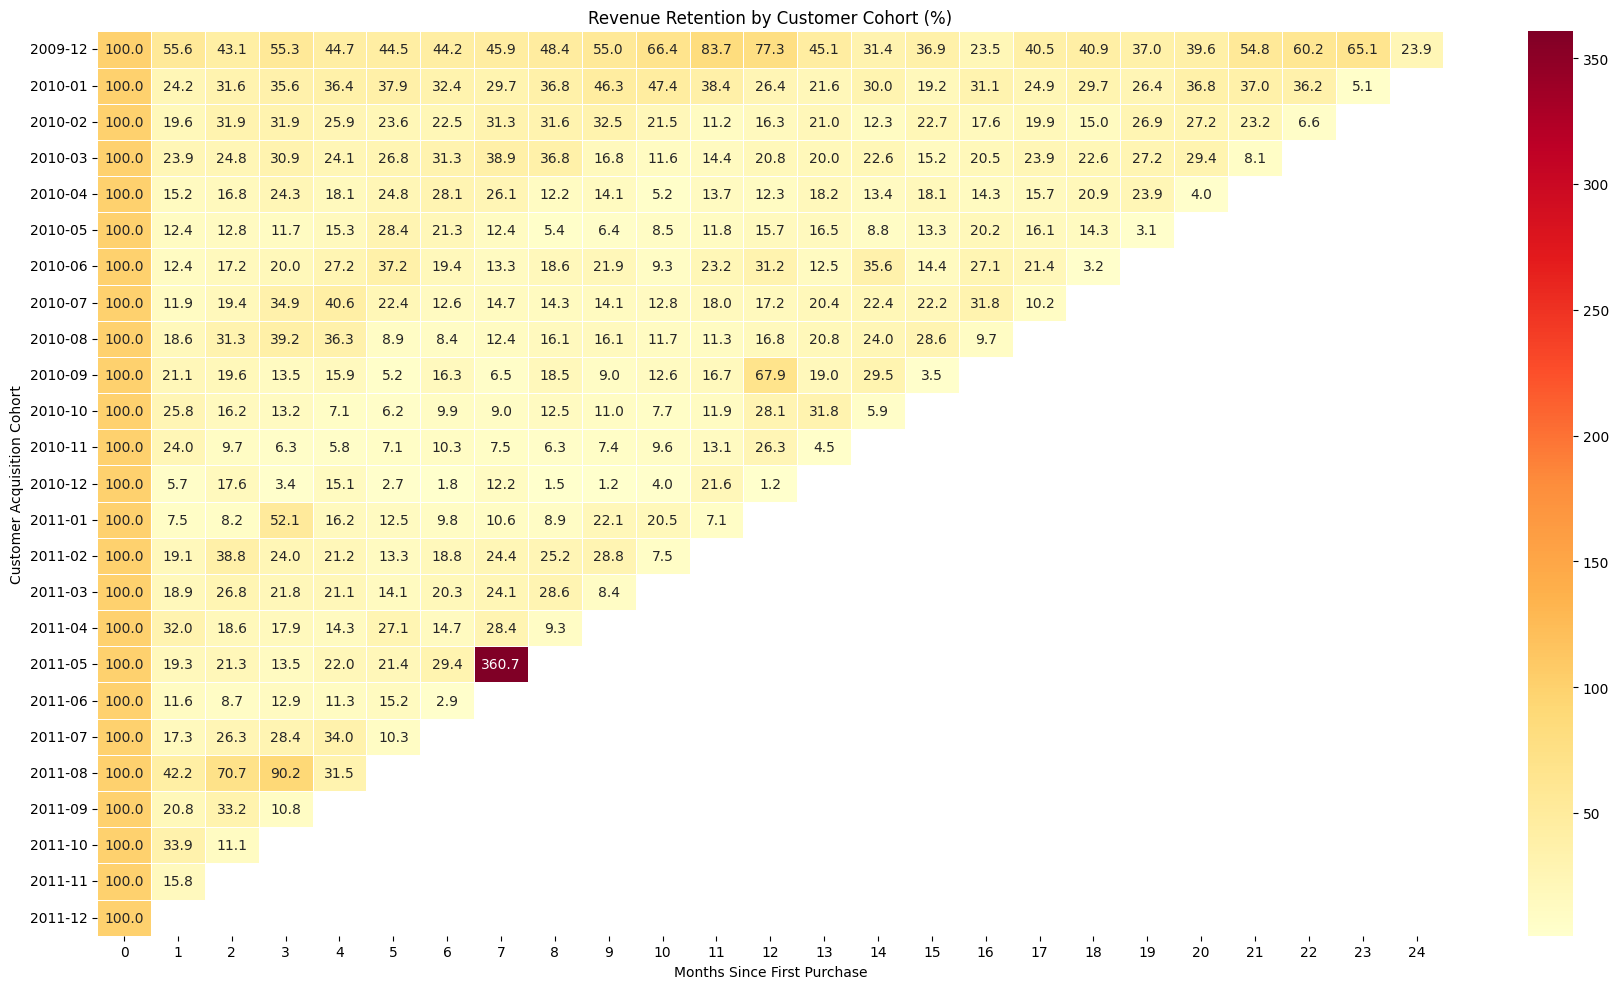

In [30]:
plt.figure(figsize=(18, 10))

sns.heatmap(
    revenue_retention,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    mask=revenue_retention.isna()
)

plt.title("Revenue Retention by Customer Cohort (%)")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Acquisition Cohort")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "revenue_retention_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
cumulative_revenue = cohort_revenue.fillna(0).cumsum(axis=1)

# Restore unavailable future periods as NaN
for cohort in cumulative_revenue.index:
    max_index = (last_month - cohort).n

    cumulative_revenue.loc[
        cohort,
        cumulative_revenue.columns > max_index
    ] = np.nan

display(cumulative_revenue.round(2))

month_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
cohort_month,,,,,,,,,,,,,,,,,,,,,,,,,
2009-12,"681,544.72","1,060,250.92","1,353,956.23","1,730,775.30","2,035,319.82","2,338,632.31","2,639,834.04","2,952,556.27","3,282,088.33","3,656,783.11","4,109,280.30","4,679,516.60","5,206,576.42","5,514,290.98","5,728,405.14","5,979,694.00","6,139,781.41","6,415,810.32","6,694,794.07","6,946,857.61","7,216,828.45","7,590,592.72","8,001,213.35","8,444,848.84","8,607,374.17"
2010-01,"160,301.69","199,143.74","249,760.63","306,792.57","365,055.03","425,837.04","477,716.99","525,279.16","584,307.50","658,591.87","734,641.47","796,148.71","838,454.68","873,066.58","921,113.93","951,946.15","1,001,772.98","1,041,674.09","1,089,256.60","1,131,535.84","1,190,581.60","1,249,811.04","1,307,899.06","1,316,131.17",NaN
2010-02,"167,417.32","200,237.26","253,626.53","307,035.19","350,337.73","389,928.76","427,616.39","480,077.08","532,955.82","587,393.74","623,390.90","642,177.38","669,440.02","704,594.90","725,143.16","763,076.92","792,530.50","825,829.02","851,004.66","896,088.16","941,582.70","980,438.58","991,496.14",NaN,NaN
2010-03,"208,721.29","258,646.73","310,397.41","374,803.82","425,100.54","481,083.34","546,371.91","627,460.33","704,214.75","739,255.03","763,405.49","793,421.78","836,838.05","878,622.67","925,756.89","957,422.04","1,000,258.28","1,050,234.99","1,097,450.23","1,154,306.40","1,215,732.99","1,232,585.73",NaN,NaN,NaN
2010-04,"123,280.10","142,062.45","162,759.69","192,695.54","214,948.98","245,563.30","280,174.70","312,300.75","327,331.95","344,706.47","351,164.56","368,004.04","383,214.95","405,600.09","422,090.83","444,430.58","462,103.97","481,453.55","507,173.99","536,590.19","541,515.16",NaN,NaN,NaN,NaN
2010-05,"109,599.90","123,192.40","137,281.45","150,086.63","166,897.94","198,003.70","221,371.21","234,997.70","240,880.97","247,905.18","257,180.01","270,120.97","287,331.57","305,387.82","315,018.86","329,609.81","351,725.49","369,417.31","385,139.30","388,561.94",NaN,NaN,NaN,NaN,NaN
2010-06,"128,733.47","144,729.83","166,920.64","192,699.69","227,674.83","275,618.44","300,592.83","317,728.06","341,609.03","369,771.33","381,771.68","411,648.36","451,773.01","467,855.43","513,667.07","532,189.09","567,042.79","594,642.04","598,769.68",NaN,NaN,NaN,NaN,NaN,NaN
2010-07,"69,597.34","77,859.24","91,362.87","115,682.52","143,923.82","159,479.09","168,223.89","178,441.29","188,378.87","198,177.24","207,098.68","219,601.79","231,606.51","245,821.18","261,399.01","276,864.64","299,008.76","306,074.06",NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,"60,883.23","72,224.48","91,273.80","115,138.34","137,243.11","142,675.70","147,793.83","155,319.77","165,095.90","174,905.11","182,052.55","188,948.33","199,149.58","211,785.77","226,395.47","243,790.51","249,712.40",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [32]:
revenue_per_customer = cumulative_revenue.divide(
    cohort_sizes,
    axis=0
)

display(revenue_per_customer.round(2))

month_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
cohort_month,,,,,,,,,,,,,,,,,,,,,,,,,
2009-12,715.91,"1,113.71","1,422.22","1,818.04","2,137.94","2,456.55","2,772.93","3,101.42","3,447.57","3,841.16","4,316.47","4,915.46","5,469.09","5,792.32","6,017.23","6,281.19","6,449.35","6,739.30","7,032.35","7,297.12","7,580.70","7,973.31","8,404.64","8,870.64","9,041.36"
2010-01,419.64,521.32,653.82,803.12,955.64,"1,114.76","1,250.57","1,375.08","1,529.60","1,724.06","1,923.15","2,084.16","2,194.91","2,285.51","2,411.29","2,492.01","2,622.44","2,726.90","2,851.46","2,962.14","3,116.71","3,271.76","3,423.82","3,445.37",NaN
2010-02,446.45,533.97,676.34,818.76,934.23,"1,039.81","1,140.31","1,280.21","1,421.22","1,566.38","1,662.38","1,712.47","1,785.17","1,878.92","1,933.72","2,034.87","2,113.41","2,202.21","2,269.35","2,389.57","2,510.89","2,614.50","2,643.99",NaN,NaN
2010-03,475.45,589.17,707.06,853.77,968.34,"1,095.86","1,244.58","1,429.29","1,604.13","1,683.95","1,738.96","1,807.34","1,906.24","2,001.42","2,108.79","2,180.92","2,278.49","2,392.33","2,499.89","2,629.40","2,769.32","2,807.71",NaN,NaN,NaN
2010-04,420.75,484.85,555.49,657.66,733.61,838.10,956.23,"1,065.87","1,117.17","1,176.47","1,198.51","1,255.99","1,307.90","1,384.30","1,440.58","1,516.83","1,577.15","1,643.19","1,730.97","1,831.37","1,848.17",NaN,NaN,NaN,NaN
2010-05,431.50,485.01,540.48,590.89,657.08,779.54,871.54,925.19,948.35,976.00,"1,012.52","1,063.47","1,131.23","1,202.31","1,240.23","1,297.68","1,384.75","1,454.40","1,516.30","1,529.77",NaN,NaN,NaN,NaN,NaN
2010-06,482.15,542.06,625.17,721.72,852.71,"1,032.28","1,125.82","1,189.99","1,279.43","1,384.91","1,429.86","1,541.75","1,692.03","1,752.27","1,923.85","1,993.22","2,123.76","2,227.12","2,242.58",NaN,NaN,NaN,NaN,NaN,NaN
2010-07,374.18,418.60,491.20,621.95,773.78,857.41,904.43,959.36,"1,012.79","1,065.47","1,113.43","1,180.65","1,245.20","1,321.62","1,405.37","1,488.52","1,607.57","1,645.56",NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,375.82,445.83,563.42,710.73,847.18,880.71,912.31,958.76,"1,019.11","1,079.66","1,123.78","1,166.35","1,229.32","1,307.32","1,397.50","1,504.88","1,541.43",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


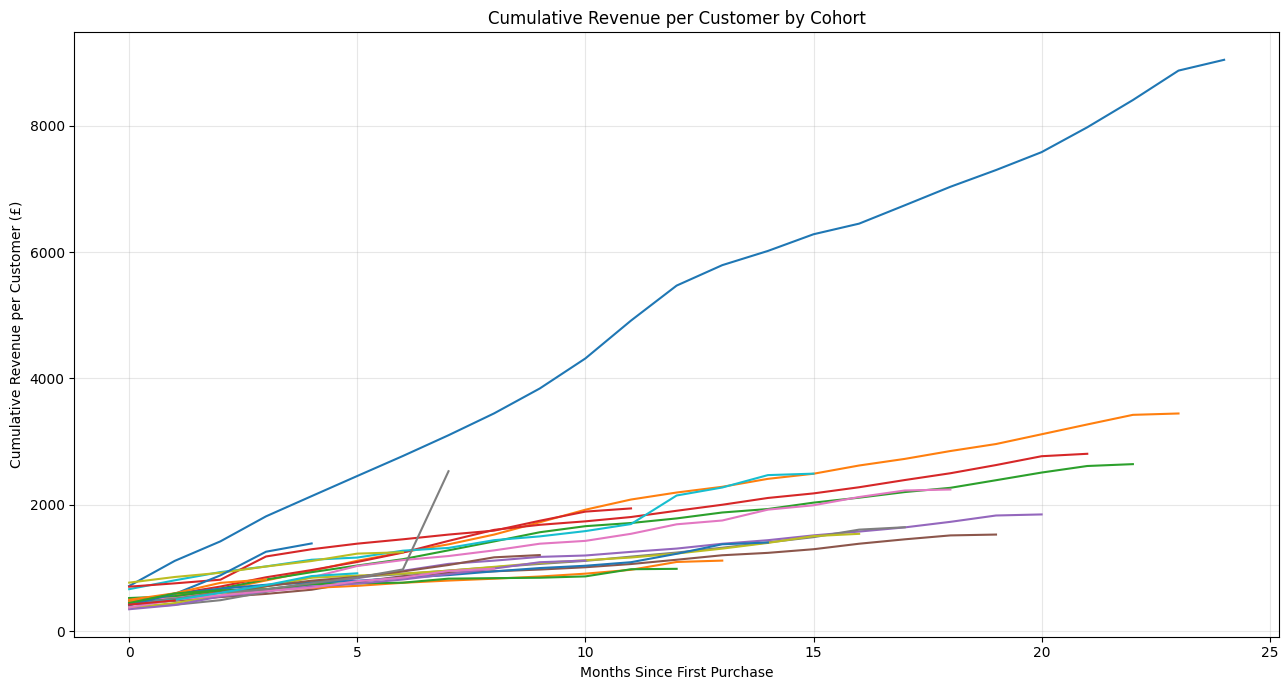

In [33]:
plt.figure(figsize=(13, 7))

for cohort in revenue_per_customer.index:
    plt.plot(
        revenue_per_customer.columns,
        revenue_per_customer.loc[cohort],
        label=str(cohort)
    )

plt.title("Cumulative Revenue per Customer by Cohort")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Cumulative Revenue per Customer (£)")
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    CHART_DIR / "cumulative_revenue_per_customer.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
may_2011_spike = clean_df[
    (clean_df["cohort_month"] == pd.Period("2011-05", freq="M")) &
    (clean_df["month_index"] == 7)
].copy()

spike_customers = (
    may_2011_spike.groupby("Customer ID")
    .agg(
        revenue=("revenue", "sum"),
        orders=("Invoice", "nunique"),
        units=("Quantity", "sum")
    )
    .sort_values("revenue", ascending=False)
)

display(spike_customers.head(10))

,revenue,orders,units
Customer ID,,,
16446,"168,469.60",1,80995
12700,"1,188.75",1,694
15187,832.48,3,310
15907,437.08,1,252
14397,429.20,2,328
15804,329.05,1,278
12684,161.40,1,84
16076,160.98,1,82
17522,158.46,1,102


In [35]:
customer_summary = clean_df.groupby("Customer ID").agg(
    total_revenue=("revenue", "sum"),
    total_orders=("Invoice", "nunique"),
    first_purchase=("InvoiceDate", "min"),
    last_purchase=("InvoiceDate", "max"),
    country=("Country", "first")
)

customer_summary["average_order_value"] = (
    customer_summary["total_revenue"] /
    customer_summary["total_orders"]
)

customer_summary["historical_clv_revenue"] = (
    customer_summary["total_revenue"]
)

display(
    customer_summary.sort_values(
        "historical_clv_revenue",
        ascending=False
    ).head(10)
)

,total_revenue,total_orders,first_purchase,last_purchase,country,average_order_value,historical_clv_revenue
Customer ID,,,,,,,
18102,"608,821.65",145,2009-12-01 09:24:00,2011-12-09 11:50:00,United Kingdom,"4,198.77","608,821.65"
14646,"526,751.52",145,2009-12-02 16:52:00,2011-12-08 12:12:00,Netherlands,"3,632.77","526,751.52"
14156,"305,767.92",151,2009-12-01 12:30:00,2011-11-30 10:54:00,EIRE,"2,024.95","305,767.92"
14911,"284,592.97",379,2009-12-01 11:41:00,2011-12-08 15:54:00,EIRE,750.90,"284,592.97"
17450,"246,973.09",51,2010-09-27 16:59:00,2011-12-01 13:29:00,United Kingdom,"4,842.61","246,973.09"
13694,"196,482.81",143,2009-12-04 15:26:00,2011-12-06 09:32:00,United Kingdom,"1,374.01","196,482.81"
17511,"175,603.55",60,2009-12-02 10:52:00,2011-12-07 10:12:00,United Kingdom,"2,926.73","175,603.55"
16446,"168,472.50",2,2011-05-18 09:52:00,2011-12-09 09:15:00,United Kingdom,"84,236.25","168,472.50"
16684,"147,142.77",55,2009-12-07 12:56:00,2011-12-05 14:06:00,United Kingdom,"2,675.32","147,142.77"


In [36]:
total_revenue = clean_df["revenue"].sum()

total_orders = clean_df["Invoice"].nunique()

unique_customers = clean_df["Customer ID"].nunique()

average_order_value = total_revenue / total_orders

purchase_frequency = total_orders / unique_customers

historical_clv_revenue = total_revenue / unique_customers

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Unique Customers: {unique_customers:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")
print(f"Orders per Customer: {purchase_frequency:.2f}")
print(f"Historical Revenue CLV: £{historical_clv_revenue:,.2f}")

Total Revenue: £17,464,127.68
Total Orders: 36,675
Unique Customers: 5,862
Average Order Value: £476.19
Orders per Customer: 6.26
Historical Revenue CLV: £2,979.21


In [37]:
GROSS_MARGIN = 0.35

customer_summary["historical_gross_profit_clv"] = (
    customer_summary["historical_clv_revenue"] * GROSS_MARGIN
)

average_historical_revenue_clv = (
    customer_summary["historical_clv_revenue"].mean()
)

average_historical_profit_clv = (
    customer_summary["historical_gross_profit_clv"].mean()
)

print(
    f"Average historical revenue CLV: "
    f"£{average_historical_revenue_clv:,.2f}"
)

print(
    f"Average historical gross profit CLV: "
    f"£{average_historical_profit_clv:,.2f}"
)

Average historical revenue CLV: £2,979.21
Average historical gross profit CLV: £1,042.72


In [38]:
observation_months = (
    clean_df["Order_month"].max() -
    clean_df["Order_month"].min()
).n + 1

monthly_purchase_frequency = (
    total_orders /
    (unique_customers * observation_months)
)

print("Observation months:", observation_months)

print(
    f"Average monthly purchase frequency: "
    f"{monthly_purchase_frequency:.4f}"
)

Observation months: 25
Average monthly purchase frequency: 0.2503


In [39]:
churn_scenarios = [0.10, 0.15, 0.20]

clv_scenarios = []

for churn_rate in churn_scenarios:

    predictive_clv = (
        average_order_value *
        monthly_purchase_frequency *
        GROSS_MARGIN /
        churn_rate
    )

    clv_scenarios.append({
        "Monthly Churn Rate": churn_rate,
        "Expected Lifetime (Months)": 1 / churn_rate,
        "Predictive Gross Profit CLV (£)": predictive_clv
    })

clv_scenario_df = pd.DataFrame(clv_scenarios)

display(clv_scenario_df.round(2))

,Monthly Churn Rate,Expected Lifetime (Months),Predictive Gross Profit CLV (£)
0,0.10,10.00,417.09
1,0.15,6.67,278.06
2,0.20,5.00,208.54


In [40]:
clv_comparison = pd.DataFrame({
    "CLV Method": [
        "Historical Gross Profit CLV",
        "Predictive CLV - 10% Monthly Churn",
        "Predictive CLV - 15% Monthly Churn",
        "Predictive CLV - 20% Monthly Churn"
    ],
    "CLV (£)": [
        average_historical_profit_clv,
        clv_scenario_df.loc[0, "Predictive Gross Profit CLV (£)"],
        clv_scenario_df.loc[1, "Predictive Gross Profit CLV (£)"],
        clv_scenario_df.loc[2, "Predictive Gross Profit CLV (£)"]
    ]
})

display(clv_comparison.round(2))

,CLV Method,CLV (£)
0,Historical Gross Profit CLV,"1,042.72"
1,Predictive CLV - 10% Monthly Churn,417.09
2,Predictive CLV - 15% Monthly Churn,278.06
3,Predictive CLV - 20% Monthly Churn,208.54


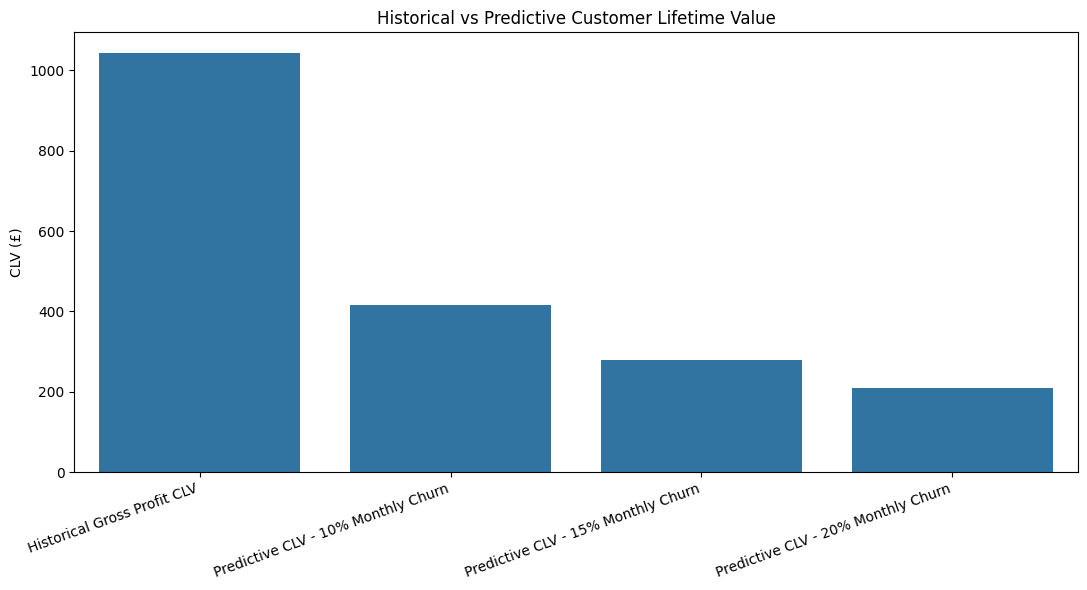

In [41]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=clv_comparison,
    x="CLV Method",
    y="CLV (£)"
)

plt.title("Historical vs Predictive Customer Lifetime Value")
plt.xlabel("")
plt.ylabel("CLV (£)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "historical_vs_predictive_clv.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
cac_scenarios = [50, 100, 200]

payback_rows = []

for _, row in clv_scenario_df.iterrows():

    for cac in cac_scenarios:

        clv = row["Predictive Gross Profit CLV (£)"]

        payback_rows.append({
            "Monthly Churn Rate": row["Monthly Churn Rate"],
            "Assumed CAC (£)": cac,
            "Predictive CLV (£)": clv,
            "CLV / CAC Ratio": clv / cac
        })

payback_df = pd.DataFrame(payback_rows)

display(payback_df.round(2))

,Monthly Churn Rate,Assumed CAC (£),Predictive CLV (£),CLV / CAC Ratio
0,0.10,50,417.09,8.34
1,0.10,100,417.09,4.17
2,0.10,200,417.09,2.09
3,0.15,50,278.06,5.56
4,0.15,100,278.06,2.78
5,0.15,200,278.06,1.39
6,0.20,50,208.54,4.17
7,0.20,100,208.54,2.09
8,0.20,200,208.54,1.04


In [43]:
country_clv = (
    customer_summary.groupby("country")
    .agg(
        customers=("historical_clv_revenue", "count"),
        total_revenue=("historical_clv_revenue", "sum"),
        average_clv=("historical_clv_revenue", "mean")
    )
    .sort_values("average_clv", ascending=False)
)

display(country_clv.head(15))

,customers,total_revenue,average_clv
country,,,
EIRE,5,"602,796.85","120,559.37"
Netherlands,22,"549,952.66","24,997.85"
Singapore,1,"13,158.16","13,158.16"
Australia,14,"162,248.82","11,589.20"
Denmark,11,"73,847.65","6,713.42"
Lithuania,1,"6,553.74","6,553.74"
Iceland,1,"5,633.32","5,633.32"
Japan,10,"47,138.39","4,713.84"
Sweden,19,"86,079.04","4,530.48"


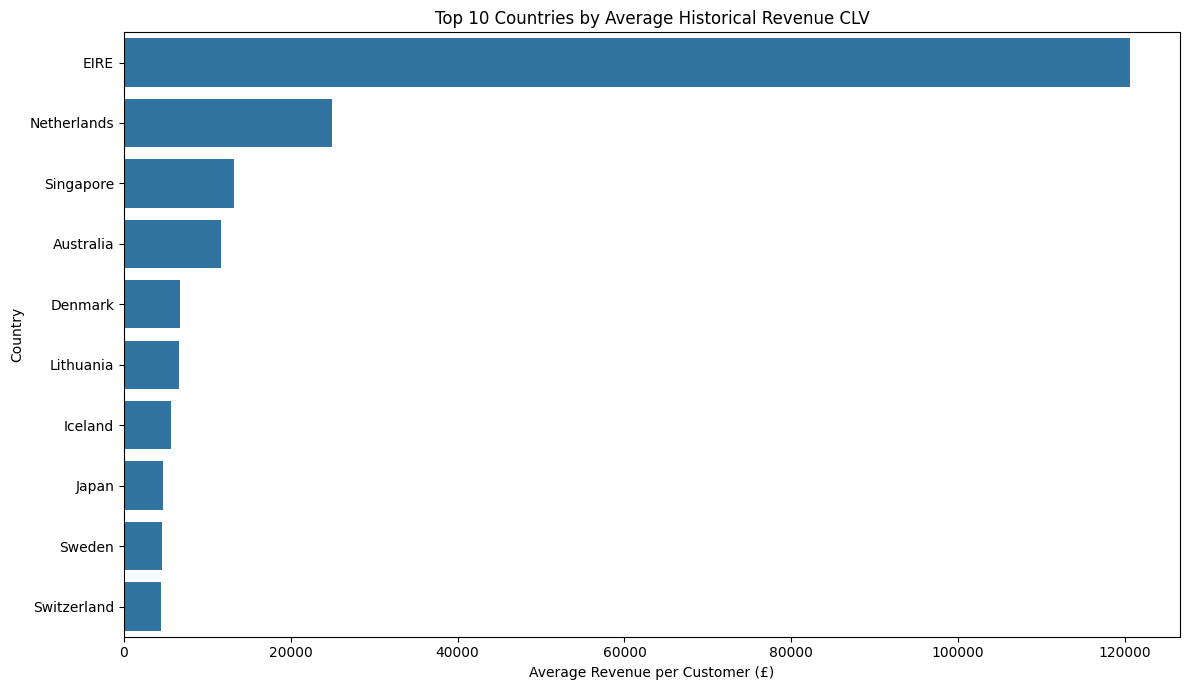

In [44]:
top_countries = country_clv.head(10).reset_index()

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_countries,
    x="average_clv",
    y="country"
)

plt.title("Top 10 Countries by Average Historical Revenue CLV")
plt.xlabel("Average Revenue per Customer (£)")
plt.ylabel("Country")
plt.tight_layout()

plt.savefig(
    CHART_DIR / "clv_by_country.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [45]:
business_metrics = pd.DataFrame({
    "Metric": [
        "Initial Dataset Rows",
        "Cleaned Dataset Rows",
        "Rows Removed",
        "Missing Customer ID Removal (%)",
        "Cancellation Rows",
        "Total Revenue (£)",
        "Total Orders",
        "Unique Customers",
        "Average Order Value (£)",
        "Purchase Frequency",
        "Historical Revenue CLV (£)",
        "Historical Gross Profit CLV (£)",
        "Assumed Gross Margin (%)",
        "Observation Months"
    ],
    "Value": [
        initial_rows,
        len(clean_df),
        initial_rows - len(clean_df),
        missing_customer_pct,
        len(cancellations),
        total_revenue,
        total_orders,
        unique_customers,
        average_order_value,
        purchase_frequency,
        historical_clv_revenue,
        average_historical_profit_clv,
        GROSS_MARGIN * 100,
        observation_months
    ]
})

display(business_metrics)

,Metric,Value
0,Initial Dataset Rows,"1,067,371.00"
1,Cleaned Dataset Rows,"802,997.00"
2,Rows Removed,"264,374.00"
3,Missing Customer ID Removal (%),22.77
4,Cancellation Rows,"18,744.00"
5,Total Revenue (£),"17,464,127.68"
6,Total Orders,"36,675.00"
7,Unique Customers,"5,862.00"
8,Average Order Value (£),476.19
9,Purchase Frequency,6.26


In [46]:
best_cohort = month_1_retention.idxmax()
worst_cohort = month_1_retention.idxmin()

best_retention = month_1_retention.max()
worst_retention = month_1_retention.min()

top_country = country_clv.index[0]
top_country_clv = country_clv.iloc[0]["average_clv"]

insights = [
    f"The cleaned dataset contains {len(clean_df):,} transaction rows "
    f"and {unique_customers:,} unique customers.",

    f"Total recorded revenue is £{total_revenue:,.2f}. "
    f"Average order value is £{average_order_value:,.2f}.",

    f"Historical revenue CLV is £{historical_clv_revenue:,.2f} "
    f"per customer over the full observation period.",

    f"The cohort with the highest observed Month 1 retention is "
    f"{best_cohort}, at {best_retention:.2f}%.",

    f"The cohort with the lowest observed Month 1 retention is "
    f"{worst_cohort}, at {worst_retention:.2f}%.",

    f"The country with the highest average historical revenue CLV "
    f"in this analysis is {top_country}, at £{top_country_clv:,.2f}.",

    "Predictive CLV depends on assumed gross margin and churn rates. "
    "These values should be treated as scenarios, not actual forecasts.",

    "CAC is not available in the dataset. Payback ratios therefore use "
    "illustrative acquisition cost assumptions."
]

insights_df = pd.DataFrame({
    "Business Insights": insights
})

display(insights_df)

,Business Insights
0,"The cleaned dataset contains 802,997 transacti..."
1,"Total recorded revenue is £17,464,127.68. Aver..."
2,"Historical revenue CLV is £2,979.21 per custom..."
3,The cohort with the highest observed Month 1 r...
4,The cohort with the lowest observed Month 1 re...
5,The country with the highest average historica...
6,Predictive CLV depends on assumed gross margin...
7,CAC is not available in the dataset. Payback r...


In [47]:
excel_path = OUTPUT_DIR / "cohort_clv_analysis.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:

    cleaning_log_df.to_excel(
        writer, sheet_name="Cleaning Log", index=False
    )

    business_metrics.to_excel(
        writer, sheet_name="Business Metrics", index=False
    )

    retention_matrix.to_excel(
        writer, sheet_name="Customer Retention"
    )

    revenue_retention.to_excel(
        writer, sheet_name="Revenue Retention"
    )

    cohort_revenue.to_excel(
        writer, sheet_name="Cohort Revenue"
    )

    cumulative_revenue.to_excel(
        writer, sheet_name="Cumulative Revenue"
    )

    revenue_per_customer.to_excel(
        writer, sheet_name="Revenue Per Customer"
    )

    clv_comparison.to_excel(
        writer, sheet_name="CLV Comparison", index=False
    )

    clv_scenario_df.to_excel(
        writer, sheet_name="CLV Scenarios", index=False
    )

    payback_df.to_excel(
        writer, sheet_name="Payback Scenarios", index=False
    )

    customer_summary.to_excel(
        writer, sheet_name="Customer Summary"
    )

    country_clv.to_excel(
        writer, sheet_name="Country CLV"
    )

    insights_df.to_excel(
        writer, sheet_name="Business Insights", index=False
    )

print("Excel workbook saved to:", excel_path)

Excel workbook saved to: ..\outputs\cohort_clv_analysis.xlsx


In [48]:
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

from openpyxl import load_workbook

wb = load_workbook(excel_path)

for ws in wb.worksheets:

    ws.freeze_panes = "B2"

    for cell in ws[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill(
            start_color="1F4E78",
            end_color="1F4E78",
            fill_type="solid"
        )
        cell.alignment = Alignment(
            horizontal="center",
            vertical="center"
        )

    for column_cells in ws.columns:

        max_length = 0
        column_letter = get_column_letter(
            column_cells[0].column
        )

        for cell in column_cells:
            if cell.value is not None:
                max_length = max(
                    max_length,
                    len(str(cell.value))
                )

        ws.column_dimensions[column_letter].width = min(
            max_length + 3, 35
        )

wb.save(excel_path)

print("Excel formatting completed.")

Excel formatting completed.
